# K-Means — Clustering
**Author:** Almeida K.K.O. (IT25103191) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Clustering (unsupervised) &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

K-Means answers a question none of the supervised models can: **does the feature space contain
natural letter structure even when the labels are hidden?** Because ground-truth labels do exist
here, they can be withheld during fitting and then used purely for external validation — an unusually
clean way to measure how much of the class structure is intrinsic to the geometry of the data rather
than learned from supervision. K-Means uses Euclidean distance, so the Stage 5 standardisation is a
prerequisite.

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, confusion_matrix)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, json
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")

# Clustering is unsupervised: fit on the FULL dataset, labels held back for validation only
X_all, y_all = X, y
print(f'Full dataset used for clustering: {X_all.shape}')


Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)
Full dataset used for clustering: (18668, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.cluster.KMeans` with `n_init=10` and a fixed `random_state` for
  reproducibility (K-Means is sensitive to centroid initialisation).
- **Primary hyperparameter:** the number of clusters `k`, tuned via the elbow method (inertia) and
  the silhouette score, then cross-checked against the known 26 letters.

In [2]:
k_values = [4, 8, 12, 16, 20, 26, 32]
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_all), 5000, replace=False)
X_sample = X_all[sample_idx]

sweep = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_sample)
    sil = silhouette_score(X_sample, km.labels_)
    sweep.append({'k': k, 'inertia': km.inertia_, 'silhouette': sil})
    print(f"k={k:>3} | inertia={km.inertia_:>10.1f} | silhouette={sil:.4f}")

sweep_df = pd.DataFrame(sweep)


k=  4 | inertia=   72893.8 | silhouette=0.1294


k=  8 | inertia=   60217.6 | silhouette=0.1312


k= 12 | inertia=   52980.4 | silhouette=0.1280


k= 16 | inertia=   47967.5 | silhouette=0.1379


k= 20 | inertia=   44522.5 | silhouette=0.1411


k= 26 | inertia=   40795.0 | silhouette=0.1396


k= 32 | inertia=   38096.5 | silhouette=0.1409


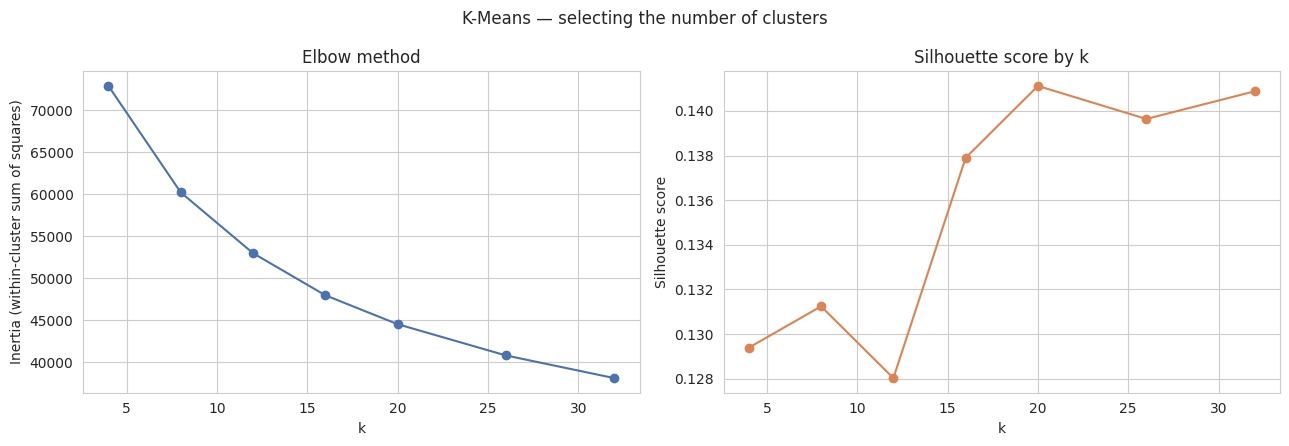

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sweep_df['k'], sweep_df['inertia'], marker='o', color='#4C72B0')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Elbow method')
axes[1].plot(sweep_df['k'], sweep_df['silhouette'], marker='o', color='#DD8452')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score by k')
plt.suptitle('K-Means — selecting the number of clusters')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_kmeans_k_selection.png', dpi=110, bbox_inches='tight')
plt.show()


## 3. Parameter Tuning — Varieties Trained

Two clustering varieties are fitted on the full dataset and compared directly: the
silhouette-preferred `k`, and `k=26` (matching the true number of letters, to test whether the
natural geometry lines up with the alphabet).

In [4]:
k_sil = int(sweep_df.loc[sweep_df['silhouette'].idxmax(), 'k'])
sil_at_k = float(sweep_df['silhouette'].max())
print(f"k preferred by silhouette score: {k_sil} (silhouette={sil_at_k:.4f})")

variants = {}
for k in sorted({k_sil, 26}):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_all)
    ari = adjusted_rand_score(y_all, km.labels_)
    nmi = normalized_mutual_info_score(y_all, km.labels_)
    variants[k] = {'inertia': km.inertia_, 'ari': ari, 'nmi': nmi, 'labels': km.labels_}
    print(f"k={k}: inertia={km.inertia_:.1f}, ARI vs true letters={ari:.4f}, NMI={nmi:.4f}")


k preferred by silhouette score: 20 (silhouette=0.1411)


k=20: inertia=167382.5, ARI vs true letters=0.1434, NMI=0.3481


k=26: inertia=154482.7, ARI vs true letters=0.1507, NMI=0.3638


## 4. Evaluation

**Metrics and why they suit this task:** accuracy is undefined for clustering because cluster IDs
carry no letter identity. Instead:
- **Silhouette score** (internal): how tight and well-separated the clusters are, using no labels.
- **Adjusted Rand Index** (external): agreement between the clustering and the true letters,
  corrected so that random assignment scores 0.
- **Normalized Mutual Information** (external): how much information the clustering shares with the
  true labels, on a 0-1 scale.

**Validation method:** the k-sweep is run on a fixed 5,000-row random sample for tractability, and
the two final varieties are refitted on all 18,668 rows before external validation.

In [5]:
kmeans_metrics = {
    'k_chosen': 26,
    'inertia': float(variants[26]['inertia']),
    'ari_vs_true_letters': float(variants[26]['ari']),
    'nmi_vs_true_letters': float(variants[26]['nmi']),
    'silhouette_preferred_k': k_sil,
    'silhouette_at_preferred_k': sil_at_k,
    'ari_at_silhouette_k': float(variants[k_sil]['ari']),
    'nmi_at_silhouette_k': float(variants[k_sil]['nmi']),
}
for k, v in kmeans_metrics.items():
    print(f"{k}: {v}")


k_chosen: 26
inertia: 154482.73576874565
ari_vs_true_letters: 0.1506950817966155
nmi_vs_true_letters: 0.3637691561241344
silhouette_preferred_k: 20
silhouette_at_preferred_k: 0.14111899277698717
ari_at_silhouette_k: 0.14343806484361993
nmi_at_silhouette_k: 0.3480891551813888


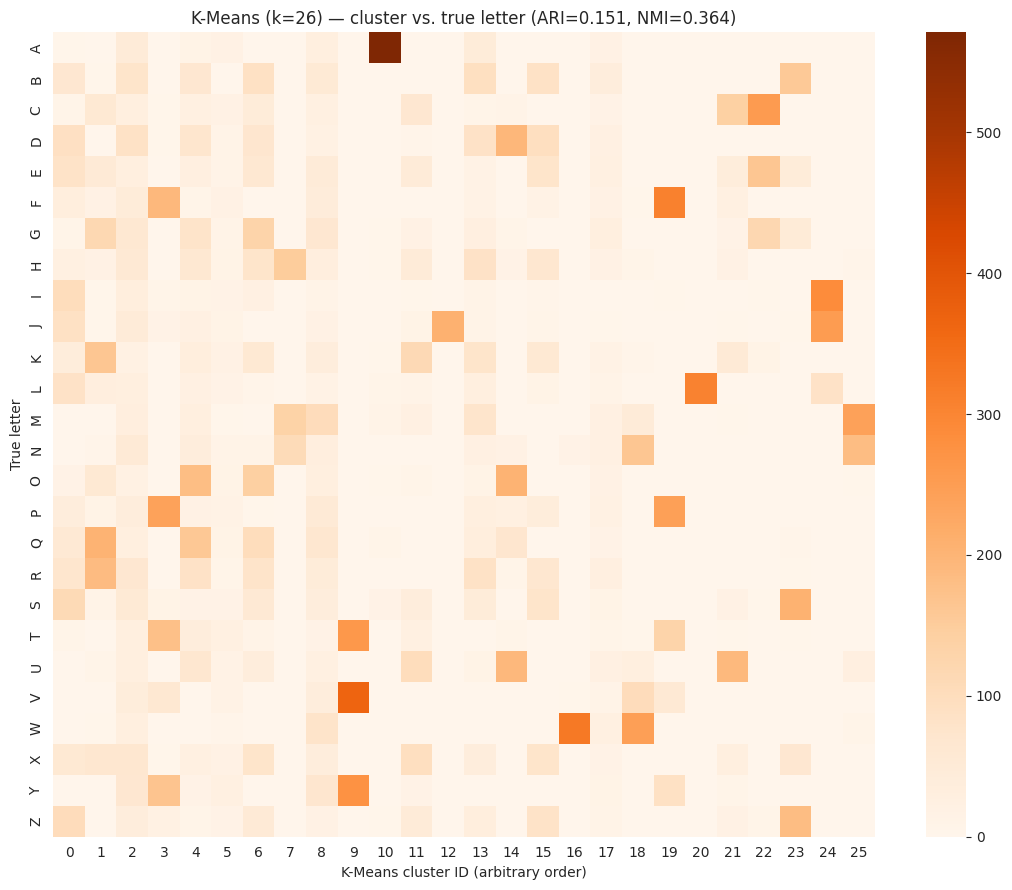

In [6]:
cm = confusion_matrix(y_all, variants[26]['labels'])
plt.figure(figsize=(11, 9))
sns.heatmap(cm, yticklabels=LETTER_NAMES, cmap='Oranges')
plt.xlabel('K-Means cluster ID (arbitrary order)'); plt.ylabel('True letter')
plt.title(f"K-Means (k=26) — cluster vs. true letter "
          f"(ARI={kmeans_metrics['ari_vs_true_letters']:.3f}, NMI={kmeans_metrics['nmi_vs_true_letters']:.3f})")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_kmeans_clusters_vs_truth.png', dpi=110, bbox_inches='tight')
plt.show()


## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison:** the two varieties disagree instructively. The silhouette score peaks at a `k` far
below 26, meaning the data's *geometrically* cleanest partition is a handful of broad letter
families rather than 26 distinct groups. Yet `k=26` scores substantially higher on both ARI and
NMI, because forcing the alphabet's granularity recovers more actual label information even though
the resulting clusters are less tidy.

**Conclusion:** `k=26` is selected as the final configuration, since the external agreement metrics
matter more than internal tidiness for this problem. ARI and NMI are both well above 0 (random
assignment) but far below what every supervised model achieves, confirming that genuine but only
partial letter structure exists without supervision — exactly the expected result for 26 visually
overlapping classes.

**Limitations / improvements:**
- K-Means assumes spherical, equally-sized clusters, which letter-shape classes are not; a Gaussian
  Mixture Model or spectral clustering could capture elongated or irregular groupings better.
- Running the k-sweep on a 5,000-row sample trades a little precision for runtime; a full sweep
  would refine the silhouette curve.

In [7]:
RESULTS_KMEANS = {
    'member': 'Almeida K.K.O. (IT25103191)',
    'model_family': 'K-Means (Clustering)',
    **kmeans_metrics,
}
with open('../results/model_metrics/kmeans_results.json', 'w') as f:
    json.dump(RESULTS_KMEANS, f, indent=2, default=str)
print(json.dumps(RESULTS_KMEANS, indent=2, default=str))


{
  "member": "Almeida K.K.O. (IT25103191)",
  "model_family": "K-Means (Clustering)",
  "k_chosen": 26,
  "inertia": 154482.73576874565,
  "ari_vs_true_letters": 0.1506950817966155,
  "nmi_vs_true_letters": 0.3637691561241344,
  "silhouette_preferred_k": 20,
  "silhouette_at_preferred_k": 0.14111899277698717,
  "ari_at_silhouette_k": 0.14343806484361993,
  "nmi_at_silhouette_k": 0.3480891551813888
}
